# 05 · Permutation importance of the best 15 March RF (5 folds, grouped)

Which inputs does the selected 15 March forest (small sample) rely on?

- **Permutation importance (PI):** shuffle a feature in the validation rows and measure how much the validation MAE
  rises (in days). The station reference is kept fixed, so PI measures the forest's anomaly part.
- **All five folds:** the model is refitted on each fold's training years; PI is computed on that fold's validation
  years with 10 shuffles (`rng = default_rng(42 + fold)`), then averaged over folds (SD across folds shown as error bars).
- **Groups:** many weather features are strongly correlated, so shuffling one at a time understates them (the forest
  uses a correlated partner instead). Features with |Spearman ρ| ≥ 0.8 are clustered (complete linkage) using the
  **fold 1 training years (1964–2004) only**, and each group is shuffled together. 36 features → 19 groups.

| | |
|---|---|
| Input | `results/rf/02_anomaly_grid/mar15_small_grid_search_all_candidates.csv`, `results/rf/03_mar15_refined/…grid_search_all_candidates.csv` |
| Output | `results/rf/05_permutation_importance/` |
| Runtime | about 3–5 minutes on 2 CPUs (5 fits + predictions) |

Main result: the 1–14 March temperature group (5 features) raises MAE by about 1.13 days when shuffled, far ahead of
latitude & longitude (0.27) and February temperature (0.17). PI is predictive, not causal.

In [1]:
import time
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from IPython.display import display

from rf_common import *

OUTPUT_OVERRIDE = None   # None = results/rf/05_permutation_importance
N_REPEATS = 10
CORR_THRESHOLD = 0.80
N_JOBS = 2

OUT = output_dir('05_permutation_importance', OUTPUT_OVERRIDE)

# The selected model: the lower-MAE of the initial (02) and refined (03) 15 March small-sample grids
initial_best = best_row(read_csv(RF_RESULTS / '02_anomaly_grid/mar15_small_grid_search_all_candidates.csv'))
refined_best = best_row(read_csv(
    RF_RESULTS / '03_mar15_refined/mar15_small_refined_grid_search_all_candidates.csv'))
if refined_best['valid_MAE'] < initial_best['valid_MAE']:
    chosen, selected_search = refined_best, 'refined (03)'
else:
    chosen, selected_search = initial_best, 'initial (02)'
BEST_PARAMS = parse_params(chosen)

data = load_sample('mar15', 'small', development_only=True)
FEATURES = feature_columns(data)
if len(FEATURES) != 36:
    raise ValueError(f'Expected 36 features, found {len(FEATURES)}')

print('Selected search:', selected_search)
print('Parameters:', BEST_PARAMS)
print(f"Saved CV MAE: {chosen['valid_MAE']:.5f}")
print('Results go to:', OUT)

Selected search: refined (03)
Parameters: {'n_estimators': 500, 'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 0.7}
Saved CV MAE: 3.04647
Results go to: /home/claude/sakura_analytics/results/rf/05_permutation_importance


## 1. Fixed feature groups from the fold 1 training years

In [2]:
cluster_train = data.loc[data['fold1'] == 'train']
# Fold 1's training years are inside every later fold's training years, so the groups never see validation data.
for fold in range(1, 6):
    if not cluster_train[f'fold{fold}'].eq('train').all():
        raise ValueError(f'Clustering rows fall outside fold {fold} training data')

constant = [c for c in FEATURES if cluster_train[c].nunique() <= 1]
varying = [c for c in FEATURES if c not in constant]

correlation = cluster_train[varying].corr(method='spearman')
distance = 1 - correlation.abs().to_numpy()
distance = np.clip((distance + distance.T) / 2, 0, 1)
np.fill_diagonal(distance, 0)
cluster_ids = fcluster(linkage(squareform(distance, checks=True), method='complete'),
                       t=1 - CORR_THRESHOLD, criterion='distance')

groups = {}
for cluster_id in sorted(set(cluster_ids)):
    groups[f'G{len(groups) + 1:02d}'] = [f for f, c in zip(varying, cluster_ids) if c == cluster_id]
for feature in constant:                  # constant columns: one group each
    groups[f'G{len(groups) + 1:02d}'] = [feature]
feature_to_group = {f: g for g, members in groups.items() for f in members}

membership = pd.DataFrame([
    {'group': g, 'n_features': len(m), 'features': ' | '.join(m)} for g, m in groups.items()
])
save_csv(membership, OUT / 'group_membership.csv')
save_json({
    'dataset': 'Mar15-small', 'selected_search': selected_search, 'best_params': BEST_PARAMS,
    'saved_cv_mae': float(chosen['valid_MAE']), 'n_repeats': N_REPEATS,
    'random_state': RANDOM_STATE, 'correlation': 'spearman', 'linkage': 'complete',
    'absolute_correlation_threshold': CORR_THRESHOLD,
    'clustering_years': [int(cluster_train['bloom_year'].min()), int(cluster_train['bloom_year'].max())],
    'groups': groups,
}, OUT / 'config.json')

print(f'{len(FEATURES)} features -> {len(groups)} groups '
      f"(clustered on {cluster_train['bloom_year'].min()}–{cluster_train['bloom_year'].max()})")
with pd.option_context('display.max_colwidth', None):
    display(membership)

36 features -> 19 groups (clustered on 1964–2004)


,group,n_features,features
0,G01,1,precip_feb_mm
1,G02,1,sunshine_feb_h
2,G03,1,precip_mar1_14_mm
3,G04,1,sunshine_mar1_14_h
4,G05,1,chill_days_0_7c_nov_feb
5,G06,1,chill_days_0_7c_mar1_14
6,G07,2,tmean_oct | tmean_nov
7,G08,2,tmin_mar1_14 | frost_days_mar1_14
8,G09,6,tmean_dec | tmean_jan | tmin_jan | tmin_feb | tmin_lowest_nov_feb | frost_days_jan_feb
9,G10,2,latitude | longitude


## 2. Refit each fold and shuffle

In [3]:
individual_rows, group_rows, baseline_rows = [], [], []
started = time.perf_counter()

for fold, train, valid in cv_folds(data):
    check_folds(train, valid, f'fold {fold}')
    model, reference = fit_anomaly_rf(train, FEATURES, BEST_PARAMS, n_jobs=N_JOBS)

    X_valid = valid[FEATURES].copy()
    actual = valid[TARGET].to_numpy(dtype=float)
    valid_reference = reference_values(reference, valid)   # held fixed while shuffling
    baseline_mae = np.mean(np.abs(model.predict(X_valid) + valid_reference - actual))
    baseline_rows.append({
        'fold': fold,
        'train_years': f"{train['bloom_year'].min()}–{train['bloom_year'].max()}",
        'valid_years': f"{valid['bloom_year'].min()}–{valid['bloom_year'].max()}",
        'valid_rows': len(valid),
        'baseline_MAE': baseline_mae,
    })

    rng = np.random.default_rng(RANDOM_STATE + fold)
    permutations = [rng.permutation(len(valid)) for _ in range(N_REPEATS)]

    def shuffle_importance(columns):
        values = []
        for permutation in permutations:
            shuffled = X_valid.copy()
            shuffled.loc[:, columns] = X_valid.iloc[permutation][columns].to_numpy()
            mae = np.mean(np.abs(model.predict(shuffled) + valid_reference - actual))
            values.append(float(mae - baseline_mae))
        return values

    individual = {}
    for feature in FEATURES:
        individual[feature] = shuffle_importance([feature])
        for repeat, value in enumerate(individual[feature], start=1):
            individual_rows.append({'fold': fold, 'feature': feature,
                                    'group': feature_to_group[feature],
                                    'repeat': repeat, 'MAE_increase_days': value})

    for group, members in groups.items():
        values = individual[members[0]] if len(members) == 1 else shuffle_importance(members)
        for repeat, value in enumerate(values, start=1):
            group_rows.append({'fold': fold, 'group': group, 'repeat': repeat,
                               'MAE_increase_days': value})

    minutes = (time.perf_counter() - started) / 60
    print(f'Fold {fold}/5 | baseline MAE {baseline_mae:.4f} | {minutes:.1f} min', flush=True)

baseline = pd.DataFrame(baseline_rows)
save_csv(baseline, OUT / 'baseline_mae_by_fold.csv')
save_csv(pd.DataFrame(individual_rows), OUT / 'individual_pi_all_repeats.csv')
save_csv(pd.DataFrame(group_rows), OUT / 'group_pi_all_repeats.csv')
display(baseline.round(4))

rebuilt = baseline['baseline_MAE'].mean()
print(f"Mean CV MAE rebuilt {rebuilt:.5f} | saved {chosen['valid_MAE']:.5f}")
if abs(rebuilt - chosen['valid_MAE']) > 0.01:
    raise ValueError('Rebuilt CV MAE differs from the saved grid search by more than 0.01 days.')

Fold 1/5 | baseline MAE 2.1175 | 1.0 min


Fold 2/5 | baseline MAE 3.0438 | 2.1 min


Fold 3/5 | baseline MAE 2.7472 | 3.2 min


Fold 4/5 | baseline MAE 2.3669 | 4.3 min


Fold 5/5 | baseline MAE 4.9570 | 5.4 min


,fold,train_years,valid_years,valid_rows,baseline_MAE
0,1,1964–2004,2005–2006,96,2.1175
1,2,1964–2006,2007–2008,96,3.0438
2,3,1964–2008,2009–2010,96,2.7472
3,4,1964–2010,2011–2012,96,2.3669
4,5,1964–2012,2013–2014,96,4.9570


Mean CV MAE rebuilt 3.04647 | saved 3.04647


## 3. Summaries: mean over folds and SD across folds

In [4]:
individual_fold = (pd.DataFrame(individual_rows)
                   .groupby(['fold', 'feature', 'group'], as_index=False)['MAE_increase_days'].mean())
group_fold = (pd.DataFrame(group_rows)
              .groupby(['fold', 'group'], as_index=False)['MAE_increase_days'].mean())

individual_summary = (
    individual_fold.groupby(['feature', 'group'])['MAE_increase_days']
    .agg(mean_PI='mean', fold_SD='std').reset_index()
    .sort_values('mean_PI', ascending=False).reset_index(drop=True)
)
group_summary = (
    group_fold.groupby('group')['MAE_increase_days']
    .agg(mean_PI='mean', fold_SD='std').reset_index()
    .merge(membership, on='group', validate='one_to_one')
    .sort_values('mean_PI', ascending=False).reset_index(drop=True)
)
group_by_fold = (group_fold.pivot(index='group', columns='fold', values='MAE_increase_days')
                 .reindex(group_summary['group']))
group_by_fold.columns = [f'fold{k}' for k in group_by_fold.columns]

save_csv(individual_fold, OUT / 'individual_pi_by_fold.csv')
save_csv(group_fold, OUT / 'group_pi_by_fold.csv')
save_csv(individual_summary, OUT / 'individual_pi_summary.csv')
save_csv(group_summary, OUT / 'group_pi_summary.csv')
save_csv(group_by_fold.reset_index(), OUT / 'group_pi_fold_comparison.csv')

with pd.option_context('display.max_colwidth', None):
    display(group_summary.round(4))
display(group_by_fold.round(4))
display(individual_summary.head(10).round(4))

,group,mean_PI,fold_SD,n_features,features
0,G11,1.1269,0.3515,5,tmean_mar1_14 | tmax_mar1_14 | gdd5_mar1_14 | cum_tmax_mar1_14 | cum_tmean_mar1_14
1,G10,0.2723,0.2643,2,latitude | longitude
2,G12,0.1733,0.2338,6,tmean_feb | tmax_feb | gdd5_feb | cum_tmax_feb | cum_tmean_feb | cum_tmax_feb1_mar14
3,G07,0.0920,0.2262,2,tmean_oct | tmean_nov
4,G09,0.0690,0.0599,6,tmean_dec | tmean_jan | tmin_jan | tmin_feb | tmin_lowest_nov_feb | frost_days_jan_feb
5,G08,0.0501,0.0392,2,tmin_mar1_14 | frost_days_mar1_14
6,G04,0.0408,0.0970,1,sunshine_mar1_14_h
7,G06,0.0283,0.0323,1,chill_days_0_7c_mar1_14
8,G13,0.0250,0.0643,1,tmax_jan
9,G02,0.0106,0.0471,1,sunshine_feb_h


,fold1,fold2,fold3,fold4,fold5
group,,,,,
G11,1.0240,0.7962,1.5660,0.8229,1.4254
G10,0.2533,0.5013,0.2182,0.5195,-0.1309
G12,0.4828,-0.1643,0.2587,0.1468,0.1422
G07,0.2543,0.0160,0.0782,0.3471,-0.2355
G09,0.1618,0.0418,0.0885,0.0042,0.0488
G08,0.0220,0.1025,0.0690,0.0028,0.0541
G04,0.0050,-0.0011,-0.0053,-0.0086,0.2140
G06,0.0130,0.0422,0.0213,-0.0104,0.0753
G13,0.0857,0.0513,0.0741,-0.0277,-0.0584


,feature,group,mean_PI,fold_SD
0,cum_tmax_mar1_14,G11,0.2382,0.1808
1,tmax_mar1_14,G11,0.1759,0.1430
2,gdd5_mar1_14,G11,0.1755,0.1552
3,latitude,G10,0.1621,0.1866
4,tmin_mar1_14,G08,0.0464,0.0397
5,tmean_dec,G09,0.0452,0.0634
6,tmin_feb,G09,0.0445,0.0429
7,cum_tmean_mar1_14,G11,0.0438,0.0310
8,tmean_mar1_14,G11,0.0418,0.0266
9,sunshine_mar1_14_h,G04,0.0408,0.0970


## 4. Figures

`pi_5fold_comparison.png`: every feature (left, grouped) and every group (right), with fold SD.
`pi_top8.png`: the top 8 features and groups only (the report figure is a restyled version of this one).

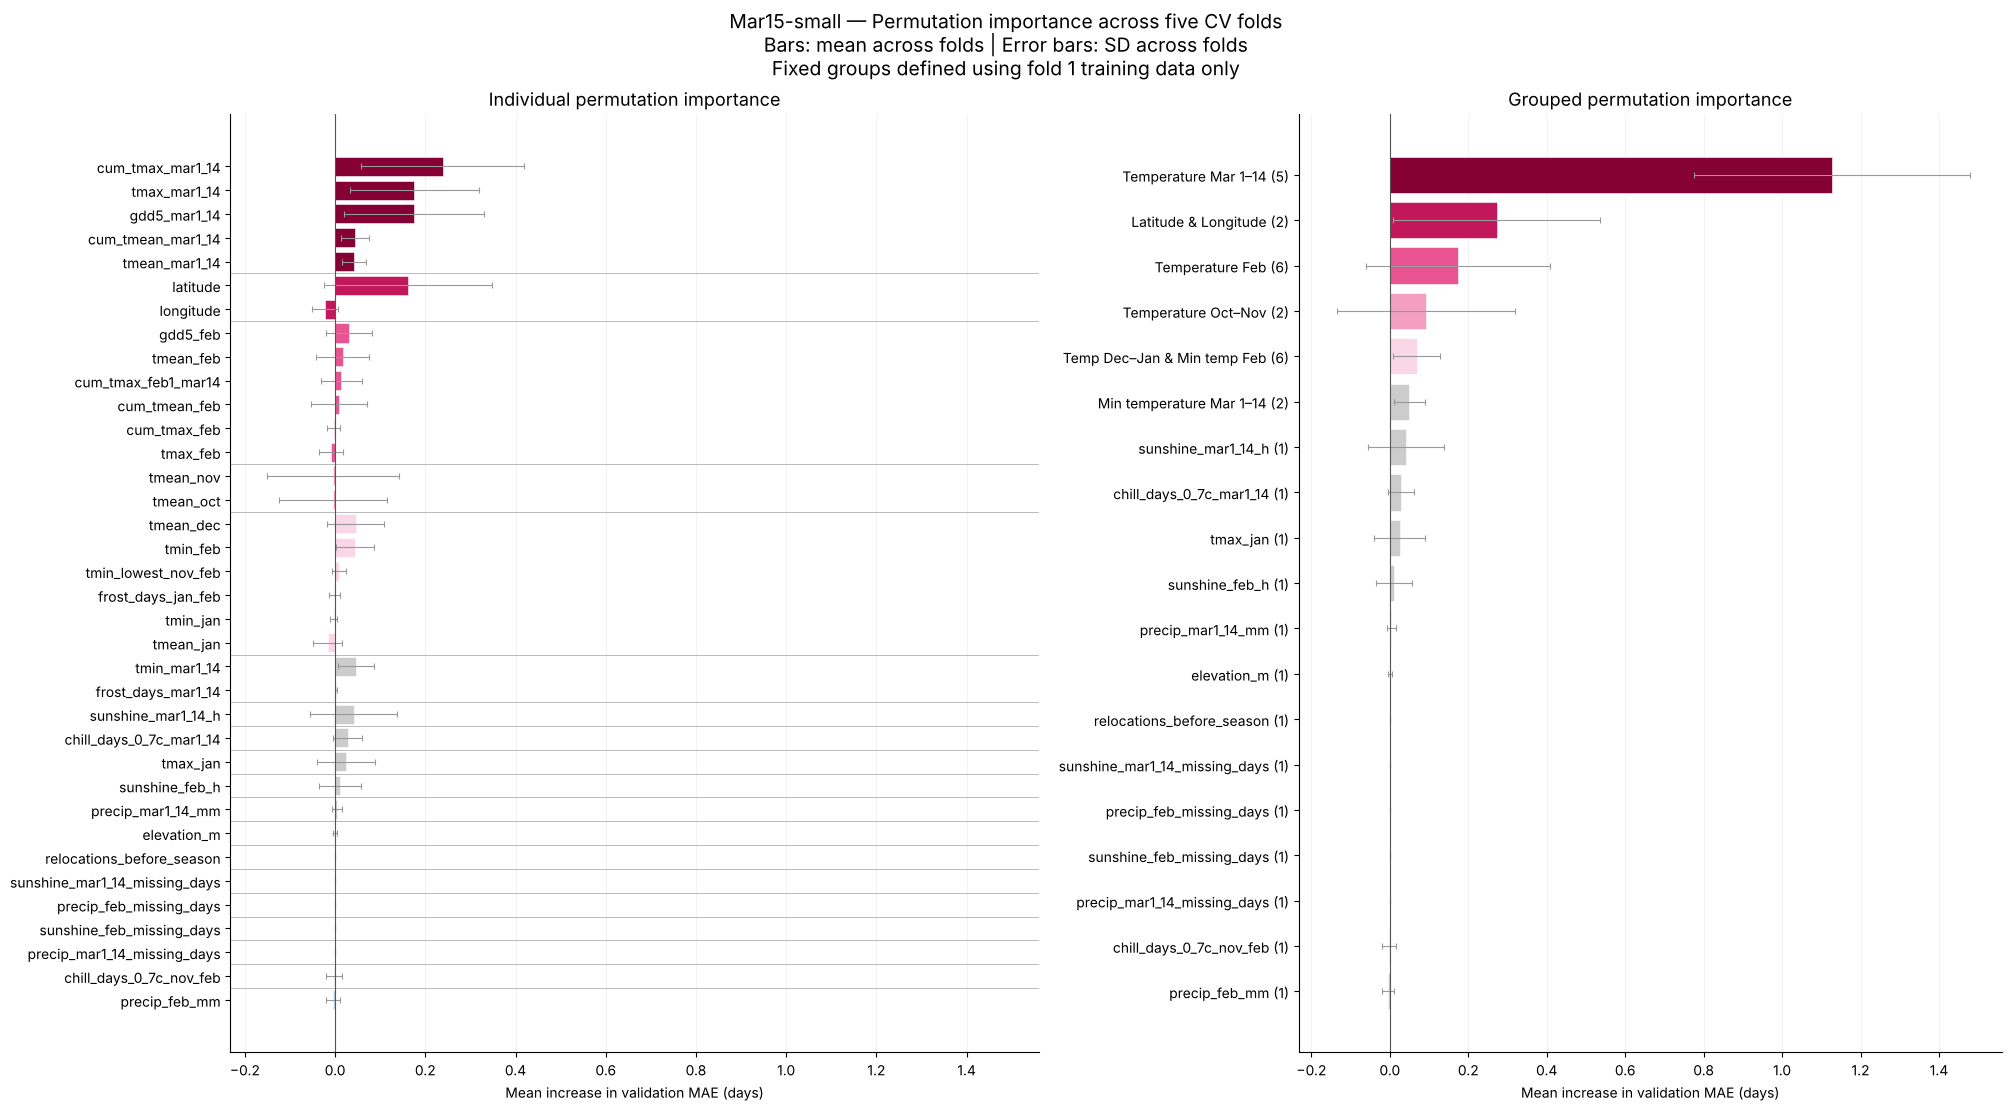

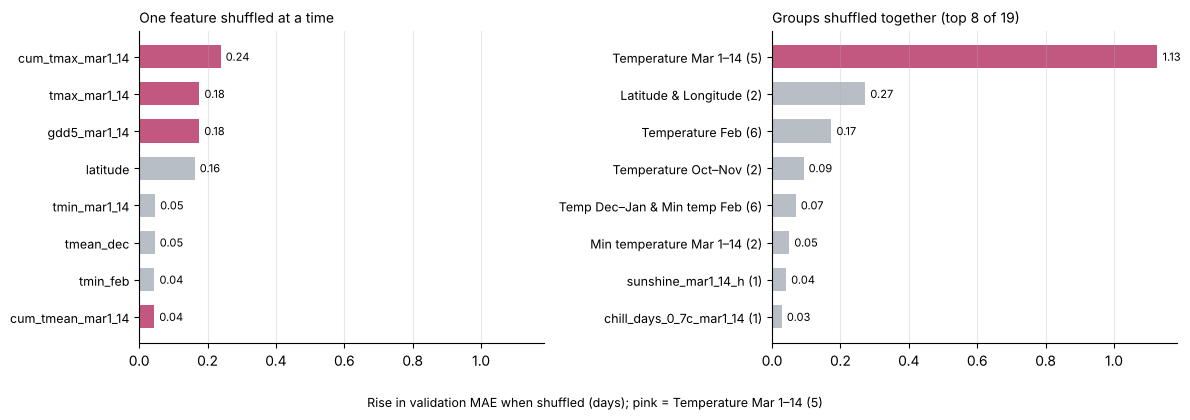

In [5]:
# Names for the groups shown in the slides/report. Group IDs come from the clustering above;
# the check below stops if the groups ever change.
GROUP_NAMES = {
    'G11': 'Temperature Mar 1–14',
    'G10': 'Latitude & Longitude',
    'G12': 'Temperature Feb',
    'G07': 'Temperature Oct–Nov',
    'G09': 'Temp Dec–Jan & Min temp Feb',
    'G08': 'Min temperature Mar 1–14',
}
expected = {'G11': 'tmean_mar1_14', 'G10': 'latitude', 'G12': 'tmean_feb'}
for group, member in expected.items():
    if member not in groups[group]:
        raise ValueError(f'Groups changed: update GROUP_NAMES ({group} has no {member})')

def group_label(group):
    members = groups[group]
    name = GROUP_NAMES.get(group, members[0] if len(members) == 1 else group)
    return f'{name} ({len(members)})'

order = group_summary['group'].tolist()
rank = {g: i for i, g in enumerate(order)}
individual_plot = (individual_summary.assign(group_rank=individual_summary['group'].map(rank))
                   .sort_values(['group_rank', 'mean_PI'], ascending=[True, False])
                   .reset_index(drop=True))

TOP5_COLORS = ['#850034', '#C2185B', '#E75491', '#F29FC1', '#FAD7E6']
group_colors = {g: '#CCCCCC' for g in order}
positive = group_summary.loc[group_summary['mean_PI'] > 0, 'group'].tolist()
for group, color in zip(positive[:5], TOP5_COLORS):
    group_colors[group] = color
for group in group_summary.loc[group_summary['mean_PI'] < 0, 'group']:
    group_colors[group] = '#B5CFDF'

fig, axes = plt.subplots(1, 2, figsize=(20, 11), sharex=True,
                         gridspec_kw={'width_ratios': [1.15, 1]}, constrained_layout=True)
for ax, table, labels, title in [
    (axes[0], individual_plot, individual_plot['feature'].tolist(), 'Individual permutation importance'),
    (axes[1], group_summary, [group_label(g) for g in group_summary['group']],
     'Grouped permutation importance'),
]:
    y = np.arange(len(table))
    ax.barh(y, table['mean_PI'], xerr=table['fold_SD'],
            color=[group_colors[g] for g in table['group']], edgecolor='white', linewidth=0.4,
            capsize=2, error_kw={'ecolor': '#999999', 'elinewidth': 0.8, 'capthick': 0.8})
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=10)
    ax.invert_yaxis()
    ax.axvline(0, color='#555555', linewidth=0.8)
    ax.set_xlabel('Mean increase in validation MAE (days)')
    ax.set_title(title, fontsize=13)
    ax.grid(axis='x', alpha=0.15)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

sequence = individual_plot['group'].tolist()
for i in range(len(sequence) - 1):
    if sequence[i] != sequence[i + 1]:
        axes[0].axhline(i + 0.5, color='#B0B0B0', linewidth=0.6, zorder=0)

fig.suptitle('Mar15-small — Permutation importance across five CV folds\n'
             'Bars: mean across folds | Error bars: SD across folds\n'
             'Fixed groups defined using fold 1 training data only', fontsize=14)
fig.savefig(OUT / 'pi_5fold_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Compact version: top 8 of each
top_group = order[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, table, labels, title in [
    (axes[0], individual_summary.head(8), individual_summary['feature'].head(8).tolist(),
     'One feature shuffled at a time'),
    (axes[1], group_summary.head(8), [group_label(g) for g in group_summary['group'].head(8)],
     f'Groups shuffled together (top 8 of {len(groups)})'),
]:
    y = np.arange(len(table))[::-1]
    ax.barh(y, table['mean_PI'], 0.62,
            color=['#C2577F' if g == top_group else '#B7BEC6' for g in table['group']])
    for yi, value in zip(y, table['mean_PI']):
        ax.text(value + 0.015, yi, f'{value:.2f}', va='center', fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_title(title, fontsize=10, loc='left')
    ax.xaxis.grid(True, alpha=0.3)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
fig.supxlabel('Rise in validation MAE when shuffled (days); pink = ' + group_label(top_group), fontsize=9)
fig.tight_layout()
fig.savefig(OUT / 'pi_top8.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()